# 02. Preguntas de Investigación

Analiza las 9 preguntas con datos existentes.  
Criterio: clásico `< 2000`, moderno `>= 2000`.  
Q1: proxy por conteo de anuncios (clasificados).  
Q6/Q9: pendientes (requieren comercializadoras/entrevistas).

In [1]:
import sys, os
sys.path.insert(0, '..')
os.chdir('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')
df = pd.read_csv('data/processed/mercado_havana.csv', encoding='utf-8-sig')
print(len(df))

3566


## Q1: Marca con mayor índice de publicaciones (proxy: anuncios)

In [2]:
q1 = df['marca'].value_counts().head(10)
q1

marca
no identificada    1110
hyundai             872
kia                 220
lada                192
toyota              148
nissan              115
honda                90
volkswagen           88
chevrolet            83
bmw                  65
Name: count, dtype: int64

## Q2: Promedio de precios por marca

In [3]:
dfp = df[df['precio_usd'].notna() & (df['precio_usd']>0)].copy()
q2 = dfp.groupby('marca')['precio_usd'].mean().sort_values(ascending=False).head(10)
q2

marca
renault            5.291016e+09
mercedes-benz      3.174640e+09
no identificada    7.325328e+04
hino               6.500000e+04
cadillac           6.313450e+04
volvo              5.666667e+04
isuzu              5.166667e+04
gmc                4.800400e+04
bmw                4.249714e+04
foton              4.159582e+04
Name: precio_usd, dtype: float64

## Q3: Relación precio-año

r= 0.3138532214114502


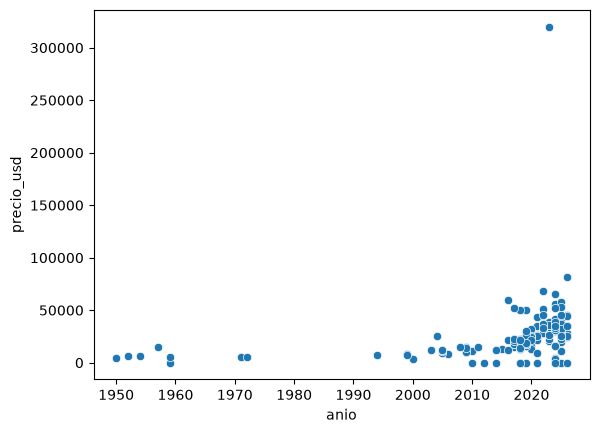

In [4]:
dfa = dfp[dfp['anio']>0].copy()
if len(dfa)>0:
    print('r=', dfa[['anio','precio_usd']].corr().iloc[0,1])
    sns.scatterplot(data=dfa.sample(n=min(200,len(dfa)), random_state=42), x='anio', y='precio_usd'); plt.savefig('reports/figuras/q3_precio_vs_anio.png', bbox_inches='tight'); plt.show()
else: print('sin datos')

## Q5: Proporción clásicos (<2000) vs modernos (>=2000)

In [5]:
dfa = df[df['anio']>0].copy()
if len(dfa)>0:
    dfa['tipo'] = dfa['anio'].apply(lambda a: 'clasico' if a < 2000 else 'moderno')
    print(dfa['tipo'].value_counts(normalize=True))
else: print('sin datos')

tipo
moderno    0.962109
clasico    0.037891
Name: proportion, dtype: float64


## Q7: Municipio con mayor índice de publicaciones

In [6]:
q7 = df['municipio'].fillna('sin_municipio').value_counts().head(10)
q7

municipio
Playa              1002
Centro Habana       472
Plaza               360
Diez de Octubre     330
Arroyo Naranjo      284
Habana del Este     180
Cerro               174
Boyeros             174
La Lisa             126
Marianao            122
Name: count, dtype: int64

## Q8: Relación municipio-precio

In [7]:
q8 = dfp.groupby('municipio')['precio_usd'].median().sort_values(ascending=False).head(10)
q8

municipio
Arroyo Naranjo           25000.0
Habana Vieja             24000.0
Centro Habana            21500.0
Playa                    21000.0
Habana del Este          18000.0
Boyeros                  18000.0
Guanabacoa               17250.0
San Miguel del Padrón    14500.0
Cerro                    12000.0
Plaza                    11000.0
Name: precio_usd, dtype: float64

## Q4: Marca con precios más elevados (top por mediana)

In [8]:
q4 = dfp.groupby('marca')['precio_usd'].median().sort_values(ascending=False).head(10)
q4

marca
cadillac      70000.0
hino          65000.0
gmc           60000.0
volvo         56000.0
foton         50000.0
isuzu         50000.0
land rover    37500.0
mazda         37000.0
lexus         36000.0
dongfeng      35000.0
Name: precio_usd, dtype: float64

## Q6 y Q9 (Pendientes)
- Q6 requiere `data/raw/comercializadoras/comercializadoras.csv` con precios (formal vs informal).  
- Q9 (costo de mantener un auto) requiere datos de las entrevistas en `data/raw/entrevistas/`.

## Q1: Marca con mayor índice de publicaciones (proxy: anuncios de Revolico)

Nota: Se trata de un *proxy* (conteo de anuncios publicados en clasificados de Revolico), no de redes sociales. Solo ámbito La Habana.

In [9]:
q1 = df['marca'].fillna('no identificada').value_counts().head(15)
q1.to_csv('reports/tablas/q1_marca_mayor_indice_publicaciones.csv')
q1

marca
no identificada    1110
hyundai             872
kia                 220
lada                192
toyota              148
nissan              115
honda                90
volkswagen           88
chevrolet            83
bmw                  65
fiat                 56
mercedes-benz        42
audi                 36
peugeot              35
dongfeng             34
Name: count, dtype: int64

## Q2: Promedio de precios por marca (mediana preferida por robustez ante outliers)

In [10]:
q2_med = dfp.groupby('marca')['precio_usd'].median().sort_values(ascending=False).head(15)
q2_med.to_csv('reports/tablas/q2_mediana_precio_por_marca.csv')
q2_med

marca
cadillac      70000.0
hino          65000.0
gmc           60000.0
volvo         56000.0
foton         50000.0
isuzu         50000.0
land rover    37500.0
mazda         37000.0
lexus         36000.0
dongfeng      35000.0
baic          33000.0
changan       33000.0
byd           32500.0
jmc           32000.0
bmw           31000.0
Name: precio_usd, dtype: float64

## Q4: Marca con los precios más elevados (mediana por marca)

In [11]:
q4 = dfp.groupby('marca')['precio_usd'].median().sort_values(ascending=False).head(15)
q4.to_csv('reports/tablas/q4_marca_precios_mas_elevados_mediana.csv')
q4

marca
cadillac      70000.0
hino          65000.0
gmc           60000.0
volvo         56000.0
foton         50000.0
isuzu         50000.0
land rover    37500.0
mazda         37000.0
lexus         36000.0
dongfeng      35000.0
baic          33000.0
changan       33000.0
byd           32500.0
jmc           32000.0
bmw           31000.0
Name: precio_usd, dtype: float64

## Q3: Relación entre precio y año de fabricación

Correlación Pearson (anio, precio_usd): 0.3139
Regresión: precio_usd = 536.74*anio + -1057799.37 (aprox 536.7 USD/año)


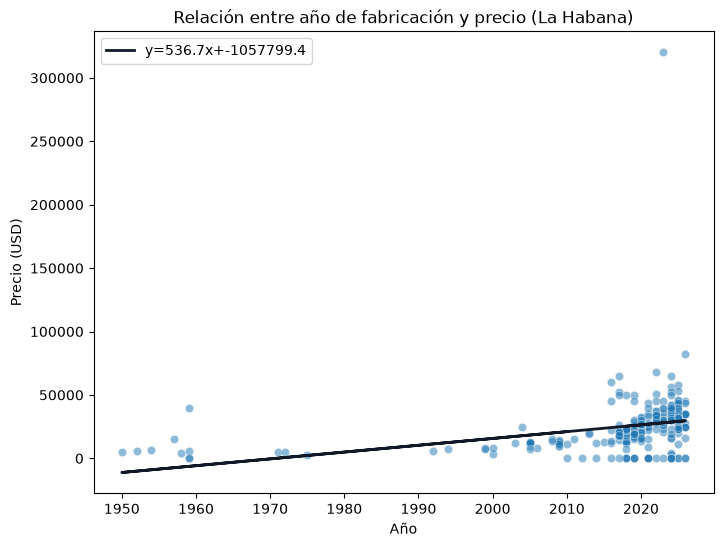

In [12]:
dfa = dfp[dfp['anio']>0].copy()
import numpy as np
if len(dfa)>0:
    corr = dfa[['anio','precio_usd']].corr().iloc[0,1]
    print(f'Correlación Pearson (anio, precio_usd): {corr:.4f}')
    # Regresión lineal simple
    x = dfa['anio']
    y = dfa['precio_usd']
    m,b = np.polyfit(x,y,1)
    print(f'Regresión: precio_usd = {m:.2f}*anio + {b:.2f} (aprox {m:.1f} USD/año)')
    plt.figure(figsize=(8,6))
    sns.scatterplot(data=dfa.sample(n=min(300,len(dfa)), random_state=42), x='anio', y='precio_usd', alpha=0.5)
    plt.plot(x, m*x+b, color='#111827', linewidth=2, label=f'y={m:.1f}x+{b:.1f}')
    plt.title('Relación entre año de fabricación y precio (La Habana)')
    plt.xlabel('Año')
    plt.ylabel('Precio (USD)')
    plt.legend()
    plt.savefig('reports/figuras/q3_precio_vs_anio_tendencia.png', bbox_inches='tight', dpi=150)
    plt.show()
else:
    print('sin datos')

## Q5: Proporción de anuncios de autos clásicos vs modernos

Criterio: clásico `< 2000`, moderno `>= 2000`

         conteo  proporcion
tipo                       
moderno    1752    0.962109
clasico      69    0.037891


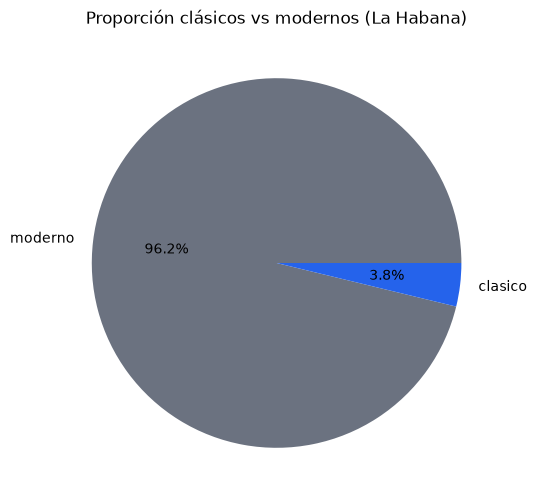

In [13]:
dfa = df[df['anio']>0].copy()
if len(dfa)>0:
    dfa['tipo'] = dfa['anio'].apply(lambda a: 'clasico' if a < 2000 else 'moderno')
    prop = dfa['tipo'].value_counts(normalize=True)
    cnt = dfa['tipo'].value_counts()
    res = pd.DataFrame({'conteo': cnt, 'proporcion': prop})
    res.to_csv('reports/tablas/q5_clasicos_vs_modernos.csv')
    print(res)
    plt.figure(figsize=(6,6))
    plt.pie(res['conteo'], labels=res.index, autopct='%1.1f%%', colors=['#6B7280','#2563EB'])
    plt.title('Proporción clásicos vs modernos (La Habana)')
    plt.savefig('reports/figuras/q5_clasicos_vs_modernos.png', bbox_inches='tight', dpi=150)
    plt.show()
else:
    print('sin datos')

## Q7: Municipio con mayor índice de publicaciones

In [14]:
q7 = df['municipio'].fillna('sin_municipio').value_counts()
q7.to_csv('reports/tablas/q7_municipio_mayor_indice_publicaciones.csv')
q7.head(15)

municipio
Playa                    1002
Centro Habana             472
Plaza                     360
Diez de Octubre           330
Arroyo Naranjo            284
Habana del Este           180
Cerro                     174
Boyeros                   174
La Lisa                   126
Marianao                  122
Guanabacoa                100
San Miguel del Padrón      99
Habana Vieja               74
Cotorro                    47
Regla                      20
Name: count, dtype: int64

## Q8: Relación entre municipio y precio de venta (mediana por municipio)

In [15]:
q8 = dfp.groupby('municipio')['precio_usd'].agg(['count','median','mean']).sort_values('median', ascending=False)
q8.to_csv('reports/tablas/q8_municipio_precio_mediana.csv')
q8.head(15)

,count,median,mean
municipio,,,
Arroyo Naranjo,267,25000.0,2.249729e+04
Habana Vieja,65,24000.0,2.064028e+04
Centro Habana,429,21500.0,2.590213e+08
Playa,917,21000.0,2.189972e+04
Habana del Este,170,18000.0,1.981427e+04
Boyeros,164,18000.0,2.126789e+04
Guanabacoa,94,17250.0,1.761229e+04
San Miguel del Padrón,85,14500.0,1.760418e+04
Cerro,153,12000.0,1.798968e+04


## Q6: Diferencia entre precios del mercado formal y el mercado informal

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar formal (comercializadoras)
formal = pd.read_csv('data/processed/comercializadoras.csv', encoding='utf-8-sig')
# Solo vehículos
formal_v = formal[formal['tipo_item']=='vehiculo'].copy()
formal_v = formal_v[formal_v['precio_usd'].notna() & (formal_v['precio_usd']>0)].copy()

# Informal La Habana (activos con precio)
informal = df[df['precio_usd'].notna() & (df['precio_usd']>0)].copy()
# Filtrar activos si existe estado_verificacion
if 'estado_verificacion' in informal.columns:
    informal_act = informal[informal['estado_verificacion']=='activo'].copy()
else:
    informal_act = informal.copy()

print('Formal (vehículos):', len(formal_v))
print('Informal La Habana (activos con precio):', len(informal_act))

# Comparación general
comp = pd.DataFrame({
  'mercado': ['formal','informal'],
  'n': [len(formal_v), len(informal_act)],
  'mediana_usd': [formal_v['precio_usd'].median(), informal_act['precio_usd'].median()],
  'media_usd': [formal_v['precio_usd'].mean(), informal_act['precio_usd'].mean()],
  'p25': [formal_v['precio_usd'].quantile(0.25), informal_act['precio_usd'].quantile(0.25)],
  'p75': [formal_v['precio_usd'].quantile(0.75), informal_act['precio_usd'].quantile(0.75)],
})
comp.to_csv('reports/tablas/q6_formal_vs_informal_comparacion.csv', index=False)
comp

Formal (vehículos): 77
Informal La Habana (activos con precio): 2443


,mercado,n,mediana_usd,media_usd,p25,p75
0,formal,77,33163.0,3.574171e+04,26781.0,42608.12
1,informal,2443,18000.0,9.098242e+07,4800.0,30000.00


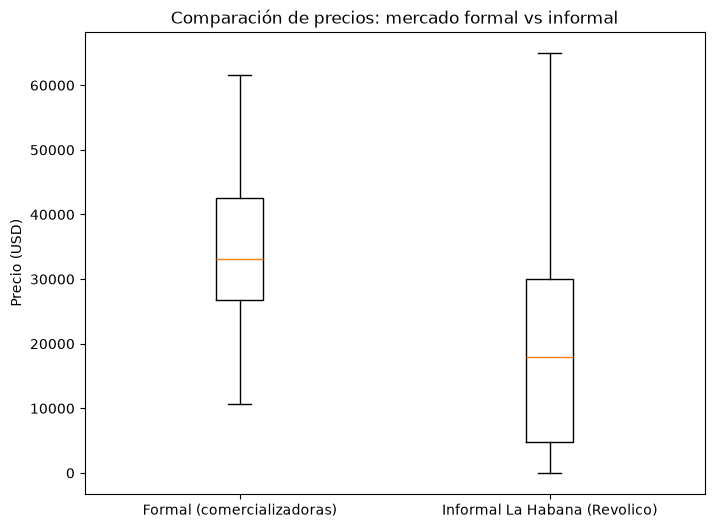

,mediana_formal,mediana_informal,diferencia_formal_informal
marca_norm,,,
mercedes-benz,72722.330,25000.0,47722.330
baic,45493.480,33000.0,12493.480
foton,44709.110,50000.0,-5290.890
dongfeng,32383.000,28300.0,4083.000
changan,30198.255,33000.0,-2801.745
maxus,24592.000,30000.0,-5408.000
mg,22896.000,21000.0,1896.000


In [17]:
# Visualización comparativa
plt.figure(figsize=(8,6))
data = [formal_v['precio_usd'], informal_act['precio_usd']]
bp = plt.boxplot(data, showfliers=False)
plt.xticks([1,2], ['Formal (comercializadoras)', 'Informal La Habana (Revolico)'])
plt.title('Comparación de precios: mercado formal vs informal')
plt.ylabel('Precio (USD)')
plt.savefig('reports/figuras/q6_formal_vs_informal_boxplot.png', bbox_inches='tight', dpi=150)
plt.show()

# Por marca donde hay cruce
formal_m = formal_v.groupby('marca_norm')['precio_usd'].median().rename('mediana_formal')
informal_m = informal_act.groupby('marca')['precio_usd'].median().rename('mediana_informal')
# normalizar marcas informales
inf_norm = informal_act.copy()
inf_norm['marca_norm'] = inf_norm['marca'].str.lower()
informal_mn = inf_norm.groupby('marca_norm')['precio_usd'].median().rename('mediana_informal')
cruce = pd.concat([formal_m, informal_mn], axis=1).dropna()
cruce['diferencia_formal_informal'] = cruce['mediana_formal'] - cruce['mediana_informal']
cruce = cruce.sort_values('mediana_formal', ascending=False)
cruce.to_csv('reports/tablas/q6_cruce_por_marca.csv')
cruce.head(15)

## Q9: ¿Cuál es el costo de mantener un auto en la actualidad?

Requiere datos de entrevistas en `data/raw/entrevistas/Audios/`. Se inventariarán audios y se dejará plantilla estructurada; sin transcripciones disponibles no se infieren cifras numéricas.

In [18]:
import os, json
from pathlib import Path

audios = list(Path('data/raw/entrevistas/Audios').glob('*'))
print('Audios encontrados:', len(audios))
for a in sorted(audios):
    print('-', a.name, a.stat().st_size, 'bytes')

plantilla = {
  'fuente': 'entrevistas',
  'requerido': ['combustible_mensual_cup_usd', 'repuestos_mensual', 'mantenimiento_preventivo_anual', 'seguro_tramites', 'otros', 'moneda'],
  'notas': 'No se inventan valores. Completar tras transcripción/validación.'
}
with open('reports/tablas/q9_plantilla_costos_mantenimiento.json','w',encoding='utf-8') as f:
    json.dump(plantilla,f,ensure_ascii=False,indent=2)
print('Plantilla guardada en reports/tablas/q9_plantilla_costos_mantenimiento.json')

Audios encontrados: 5
- Recording_3.m4a 3810041 bytes
- Recording_4.m4a 1171193 bytes
- Recording_5.m4a 1390841 bytes
- Recording_8.m4a 2393081 bytes
- Recording_9.m4a 2243321 bytes
Plantilla guardada en reports/tablas/q9_plantilla_costos_mantenimiento.json
